### Developpement d'un model IA de prédiction du marché forex avec prophet

In [61]:
import MetaTrader5 as mt5
import pandas as pd
import numpy as np
import mplfinance as mpf
from datetime import datetime

# Assurez-vous que le chemin est correct
mt5_path = "C:\\Program Files\\MetaTrader 5\\terminal64.exe"

# Initialiser MetaTrader 5
if not mt5.initialize(path=mt5_path):
    print("Erreur d'initialisation de MT5 :", mt5.last_error())  # Afficher l'erreur
    exit()

# Vérifier si la connexion au compte est active
account_info = mt5.account_info()
if account_info is None:
    print("Impossible de récupérer les informations du compte :", mt5.last_error())
    mt5.shutdown()
    exit()

print(f"Connexion réussie à MetaTrader 5 - Compte : {account_info.login}")


symbols = mt5.symbols_get()
available_symbols = [s.name for s in symbols]
print(available_symbols)
if "XAUUSDm" not in available_symbols:
    print("XAUUSDm n'est pas disponible sur votre compte MT5.")
else:
    print("XAUUSDm est bien disponible.")


# Récupérer les données XAUUSDm (10000 dernières bougies en 15M)
RISK_PERC = 2.0
symbol = "XAUUSDm"
timeframe = mt5.TIMEFRAME_M15  # Période (15 minutes)
data = mt5.copy_rates_from_pos(symbol, timeframe, 0, 10000)

# Vérifier si les données ont été récupérées
if data is None:
    print(f"Erreur lors de la récupération des données pour {symbol} :", mt5.last_error())
    mt5.shutdown()
    exit()

# Convertir en DataFrame Pandas
df = pd.DataFrame(data)
df['time'] = pd.to_datetime(df['time'], unit='s')  # Convertir timestamp en date
df.set_index('time', inplace=True)

# Afficher un aperçu des données récupérées
print(df.head())

# Ne pas fermer la connexion ici si on veut exécuter d'autres opérations après


Connexion réussie à MetaTrader 5 - Compte : 408745035
['USDAED', 'USDAMD', 'USDARS', 'USDAZN', 'USDBDT', 'USDBGN', 'USDBHD', 'USDBND', 'USDBRL', 'USDCLP', 'USDCNY', 'USDCOP', 'USDCZK', 'USDDZD', 'USDEGP', 'USDGEL', 'USDGHS', 'USDHRK', 'USDHUF', 'USDIDR', 'USDILS', 'USDINR', 'USDISK', 'USDJOD', 'USDKES', 'USDKGS', 'USDKRW', 'USDKWD', 'USDKZT', 'USDLBP', 'USDLKR', 'USDMAD', 'USDMYR', 'USDNGN', 'USDNPR', 'USDOMR', 'USDPHP', 'USDPKR', 'USDQAR', 'USDRON', 'USDSAR', 'USDSYP', 'USDTJS', 'USDTMT', 'USDTND', 'USDTWD', 'USDUAH', 'USDUGX', 'USDUZS', 'USDVND', 'USDVUV', 'USDXOF', 'USDRUB', 'USDAEDz', 'USDCLPz', 'USDCNYz', 'USDCOPz', 'USDDZDz', 'USDEGPz', 'USDGELz', 'USDGHSz', 'USDIDRz', 'USDINRz', 'USDISKz', 'USDAMDz', 'USDJODz', 'USDKESz', 'USDKGSz', 'USDKRWz', 'USDKWDz', 'USDKZTz', 'USDLBPz', 'USDLKRz', 'USDMADz', 'USDMYRz', 'USDARSz', 'USDNGNz', 'USDNPRz', 'USDOMRz', 'USDPHPz', 'USDPKRz', 'USDQARz', 'USDRONz', 'USDRUBz', 'USDRURz', 'USDSARz', 'USDAZNz', 'USDSYPz', 'USDTJSz', 'USDTMTz', 'USDTNDz

### Nous pouvons voir le nombre de symbole disponible par notre broker

In [62]:
if mt5.initialize():
    symbols = mt5.symbols_total()
    if symbols > 0:
        print(f"{symbols} symboles trouvés")
    else:
        print("Aucun symbole disponible")
    mt5.shutdown()
else:
    print("Échec de l'initialisation :", mt5.last_error())

452 symboles trouvés


In [63]:
# Calcul de l'AO et AC
df['ao'] = df['close'].rolling(window=5).mean() - df['close'].rolling(window=34).mean()  # AO simplifié
df['ac'] = df['ao'] - df['ao'].ewm(span=5, adjust=False).mean()  # AC

In [64]:
# Calculer les Bandes de Bollinger
def calculate_bollinger_bands(df, window=20):
    df['rolling_mean'] = df['close'].rolling(window=window).mean()
    df['rolling_std'] = df['close'].rolling(window=window).std()
    df['bollinger_upper'] = df['rolling_mean'] + (df['rolling_std'] * 2)
    df['bollinger_lower'] = df['rolling_mean'] - (df['rolling_std'] * 2)
    return df

df = calculate_bollinger_bands(df)


In [65]:
# Calculer le Stochastique
def calculate_stochastic(df, window=14):
    df['lowest_low'] = df['low'].rolling(window=window).min()
    df['highest_high'] = df['high'].rolling(window=window).max()
    df['stochastic'] = 100 * (df['close'] - df['lowest_low']) / (df['highest_high'] - df['lowest_low'])
    return df

df = calculate_stochastic(df)


#### Calcul des indicateurs techniques

In [66]:
import ta

# Calcul des Moyennes Mobiles Exponentielles (EMA 50 et 200)
df['ema_20'] = ta.trend.ema_indicator(df['close'], window=20)  # EMA rapide
df['ema_50'] = ta.trend.ema_indicator(df['close'], window=50)
df['ema_200'] = ta.trend.ema_indicator(df['close'], window=200)

# Calcul du RSI (14 périodes)
df['rsi'] = ta.momentum.rsi(df['close'], window=14)

# Calcul des Bollinger Bands (20 périodes)
bb = ta.volatility.BollingerBands(df['close'], window=20, window_dev=2)
df['bb_upper'] = bb.bollinger_hband()
df['bb_lower'] = bb.bollinger_lband()

## MACD (12, 26, 9)
df['macd'] = ta.trend.macd(df['close'])
df['macd_signal'] = ta.trend.macd_signal(df['close'], window_slow=26, window_fast=12, window_sign=9)
df['adx'] = ta.trend.adx(df['high'], df['low'], df['close'], window=14)

## Stochastic Oscillator (14, 3, 3)
df['stoch_k'] = ta.momentum.stoch(df['high'], df['low'], df['close'], window=14, smooth_window=3)
df['stoch_d'] = ta.momentum.stoch_signal(df['high'], df['low'], df['close'], window=14, smooth_window=3)

## Volume (Optionnel, dépend des données disponibles)
df['volume'] = df['real_volume'] if 'real_volume' in df.columns else df['tick_volume']
df['atr'] = ta.volatility.average_true_range(df['high'], df['low'], df['close'], window=14)
df['hour'] = df.index.hour


# Afficher les indicateurs
print(df.tail())
df.fillna(method='ffill', inplace=True)
df.dropna(inplace=True)


                         open      high       low     close  tick_volume  \
time                                                                       
2025-03-17 07:45:00  2986.433  2986.647  2984.087  2985.487         1318   
2025-03-17 08:00:00  2985.548  2986.686  2984.368  2984.552         1268   
2025-03-17 08:15:00  2984.482  2986.673  2983.053  2985.438         1429   
2025-03-17 08:30:00  2985.409  2987.944  2984.884  2987.610         1225   
2025-03-17 08:45:00  2987.612  2987.751  2986.313  2986.781          682   

                     spread  real_volume        ao        ac  rolling_mean  \
time                                                                         
2025-03-17 07:45:00     160            0 -0.100959 -0.164443    2986.33735   
2025-03-17 08:00:00     159            0 -0.938229 -0.667809    2986.20150   
2025-03-17 08:15:00     159            0 -1.469459 -0.799359    2986.15225   
2025-03-17 08:30:00     159            0 -1.559635 -0.593024    2986.20700   

C:\Users\user\AppData\Local\Temp\ipykernel_19960\3075200388.py:33: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method='ffill', inplace=True)


In [67]:
from prophet import Prophet
# Conversion en DataFrame pour Prophet

df = pd.DataFrame(data)
df['ds'] = pd.to_datetime(df['time'], unit='s')  # Pour Prophet
df['y'] = df['close']  # Variable à prédire

# Garder les colonnes nécessaires pour les indicateurs
df['high'] = df['high']
df['low'] = df['low']
df['close'] = df['close']

model = Prophet(daily_seasonality=True, weekly_seasonality=True, yearly_seasonality=False)
model.fit(df[['ds', 'y']])  # Entraîner uniquement sur ds et y

# Prédiction future
future = model.make_future_dataframe(periods=24, freq='H')
forecast = model.predict(future)

21:33:58 - cmdstanpy - INFO - Chain [1] start processing
21:34:06 - cmdstanpy - INFO - Chain [1] done processing
C:\Users\user\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\prophet\forecaster.py:1854: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  dates = pd.date_range(


#### Détection des Signaux d'Achat/Vente

In [68]:
import pandas as pd
import ta
from prophet import Prophet
import matplotlib.pyplot as plt

def calculate_tp_sl_with_ta(df, forecast):
    # Étendre les données historiques avec les prédictions futures
    df = df.merge(forecast[['ds', 'yhat']], on='ds', how='left')
    df['yhat'] = df['yhat'].fillna(df['y'])
    
    # Simuler les données futures en utilisant yhat comme close
    df['close'] = df['y'].fillna(df['yhat'])  # Si y est NaN (futur), utiliser yhat
    df['high'] = df['high'].fillna(df['close'] + 0.1)  # Approximation simple
    df['low'] = df['low'].fillna(df['close'] - 0.1)   # Approximation simple
    df = df.ffill()
    df = df.dropna(subset=['close'])

    # Calcul des indicateurs techniques sur toutes les données (historiques + futures)
    df['ema_20'] = ta.trend.ema_indicator(df['close'], window=20)
    df['ema_50'] = ta.trend.ema_indicator(df['close'], window=50)
    
    df['rsi'] = ta.momentum.rsi(df['close'], window=14)
    df['adx'] = ta.trend.adx(df['high'], df['low'], df['close'], window=14)
    atr_indicator = ta.volatility.AverageTrueRange(high=df['high'], low=df['low'], close=df['close'], window=14)
    df['atr'] = atr_indicator.average_true_range()

    df['buy_signal'] = False
    df['sell_signal'] = False
    df['tp'] = None
    df['sl'] = None
    df['exit'] = None  # Ajout explicite de la colonne exit

    # Conditions assouplies
    buy_condition = (
        (df['ema_20'] > df['ema_50']) &
        (df['rsi'] < 45) &
        (df['adx'] > 18) &
        (df['yhat'] - df['close'] > 0.01)
    )
    sell_condition = (
        (df['ema_20'] < df['ema_50']) &
        (df['rsi'] > 55) &
        (df['adx'] > 18) &
        (df['close'] - df['yhat'] > 0.01)
    )

    df.loc[buy_condition, 'buy_signal'] = True
    df.loc[sell_condition, 'sell_signal'] = True

    tp_sl_multiple = 2.0
    df.loc[buy_condition, 'tp'] = df['close'] + (df['atr'] * tp_sl_multiple)
    df.loc[buy_condition, 'sl'] = df['close'] - (df['atr'] * tp_sl_multiple)
    df.loc[sell_condition, 'tp'] = df['close'] - (df['atr'] * tp_sl_multiple)
    df.loc[sell_condition, 'sl'] = df['close'] + (df['atr'] * tp_sl_multiple)

    return df

def backtest_signals(df, initial_balance=500, risk_percent=2.0):
    balance = initial_balance
    position = 0
    trades = []
    trade_log = []
    equity = [initial_balance]

    for i in range(1, len(df)):
        close = df['close'].iloc[i]
        atr = df['atr'].iloc[i]
        lot_size = (balance * risk_percent / 100) / (max(atr,0.1) * 100)

        if position == 0:
            if df['buy_signal'].iloc[i]:
                position = 1
                entry_price = close
                tp = df['tp'].iloc[i]
                sl = df['sl'].iloc[i]
                trades.append({'entry': entry_price, 'type': 'buy', 'lot': lot_size, 'tp': tp, 'sl': sl})
            elif df['sell_signal'].iloc[i]:
                position = -1
                entry_price = close
                tp = df['tp'].iloc[i]
                sl = df['sl'].iloc[i]
                trades.append({'entry': entry_price, 'type': 'sell', 'lot': lot_size, 'tp': tp, 'sl': sl})
        
        elif position == 1:
            if close >= tp:
                profit = (tp - entry_price) * trades[-1]['lot'] * 100
                balance += profit
                trades[-1]['exit'] = tp
                trades[-1]['profit'] = profit
                df.loc[df.index[i], 'exit'] = tp
                position = 0
            elif close <= sl:
                loss = (sl - entry_price) * trades[-1]['lot'] * 100
                balance += loss
                trades[-1]['exit'] = sl
                trades[-1]['profit'] = loss
                df.loc[df.index[i], 'exit'] = sl
                position = 0
        
        elif position == -1:
            if close <= tp:
                profit = (entry_price - tp) * trades[-1]['lot'] * 100
                balance += profit
                trades[-1]['exit'] = tp
                trades[-1]['profit'] = profit
                df.loc[df.index[i], 'exit'] = tp
                position = 0
            elif close >= sl:
                loss = (entry_price - sl) * trades[-1]['lot'] * 100
                balance += loss
                trades[-1]['exit'] = sl
                trades[-1]['profit'] = loss
                df.loc[df.index[i], 'exit'] = sl
                position = 0
        
        equity.append(balance)

    win_rate = len([t for t in trades if t.get('profit', 0) > 0]) / len(trades) if trades else 0
    print(f"\n💰 Solde final : {balance:.2f} | Trades : {len(trades)} | Taux de réussite : {win_rate:.2%}")
    for trade in trades:
        print(trade)

    return trades, equity

# Exécution
df = calculate_tp_sl_with_ta(df, forecast)
num_buy_signals = df['buy_signal'].sum()
num_sell_signals = df['sell_signal'].sum()

print("\n📊 Signaux détectés :")
print(f"🟢 Nombre de signaux d'achat : {num_buy_signals}")
print(f"🔴 Nombre de signaux de vente : {num_sell_signals}")

# Backtest pour remplir les sorties
trades, equity = backtest_signals(df)





📊 Signaux détectés :
🟢 Nombre de signaux d'achat : 244
🔴 Nombre de signaux de vente : 156

💰 Solde final : 1880.50 | Trades : 95 | Taux de réussite : 68.42%
{'entry': np.float64(2648.174), 'type': 'buy', 'lot': np.float64(0.037534722505828545), 'tp': 2653.502399589712, 'sl': 2642.845600410288, 'exit': 2653.502399589712, 'profit': np.float64(20.000000000000338)}
{'entry': np.float64(2652.184), 'type': 'buy', 'lot': np.float64(0.03683769367804055), 'tp': 2657.8303904015793, 'sl': 2646.537609598421, 'exit': 2657.8303904015793, 'profit': np.float64(20.799999999999862)}
{'entry': np.float64(2647.751), 'type': 'buy', 'lot': np.float64(0.03705490270500561), 'tp': 2653.588823991123, 'sl': 2641.9131760088776, 'exit': 2653.588823991123, 'profit': np.float64(21.631999999999564)}
{'entry': np.float64(2648.287), 'type': 'buy', 'lot': np.float64(0.03186082885111773), 'tp': 2655.348109459872, 'sl': 2641.2258905401277, 'exit': 2655.348109459872, 'profit': np.float64(22.497279999999378)}
{'entry': np.

In [69]:
# Afficher les 10 derniers signaux
signals_detected = df[df['buy_signal'] | df['sell_signal']].tail(20)
print("\n📍 10 derniers signaux détectés (présent et futur) :")
for index, row in signals_detected.iterrows():
    signal_type = "🟢 Achat" if row['buy_signal'] else "🔴 Vente"
    exit_price = row['exit'] if 'exit' in row and pd.notna(row['exit']) else "N/A (non clôturé)"
    print(f"{row['ds']} | {signal_type} | Entrée: {row['close']:.5f} | Sortie: {exit_price} | TP: {row['tp']:.5f} | SL: {row['sl']:.5f}")



📍 10 derniers signaux détectés (présent et futur) :
2025-03-04 15:30:00 | 🟢 Achat | Entrée: 2909.36400 | Sortie: N/A (non clôturé) | TP: 2920.99875 | SL: 2897.72925
2025-03-04 15:45:00 | 🟢 Achat | Entrée: 2906.10200 | Sortie: N/A (non clôturé) | TP: 2917.78584 | SL: 2894.41816
2025-03-04 16:15:00 | 🟢 Achat | Entrée: 2908.07800 | Sortie: N/A (non clôturé) | TP: 2919.36889 | SL: 2896.78711
2025-03-04 18:30:00 | 🟢 Achat | Entrée: 2908.88800 | Sortie: N/A (non clôturé) | TP: 2918.19632 | SL: 2899.57968
2025-03-05 02:15:00 | 🟢 Achat | Entrée: 2907.11800 | Sortie: N/A (non clôturé) | TP: 2915.33191 | SL: 2898.90409
2025-03-05 13:15:00 | 🟢 Achat | Entrée: 2913.12100 | Sortie: N/A (non clôturé) | TP: 2921.13065 | SL: 2905.11135
2025-03-06 20:45:00 | 🟢 Achat | Entrée: 2908.70300 | Sortie: N/A (non clôturé) | TP: 2916.90462 | SL: 2900.50138
2025-03-06 21:00:00 | 🟢 Achat | Entrée: 2910.85400 | Sortie: N/A (non clôturé) | TP: 2918.86593 | SL: 2902.84207
2025-03-06 21:15:00 | 🟢 Achat | Entrée: 290

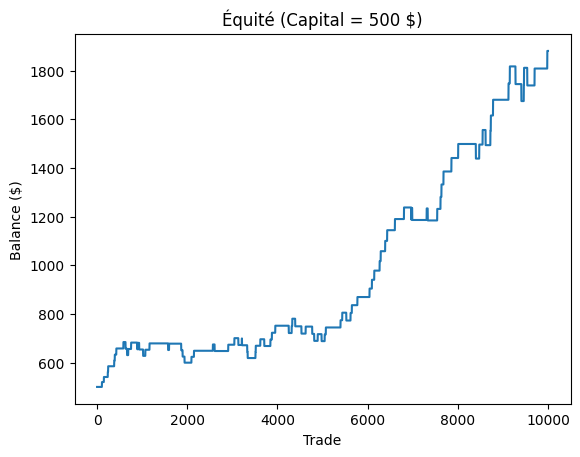

In [70]:
plt.plot(equity)
plt.title("Équité (Capital = 500 $)")
plt.xlabel("Trade")
plt.ylabel("Balance ($)")
plt.show()

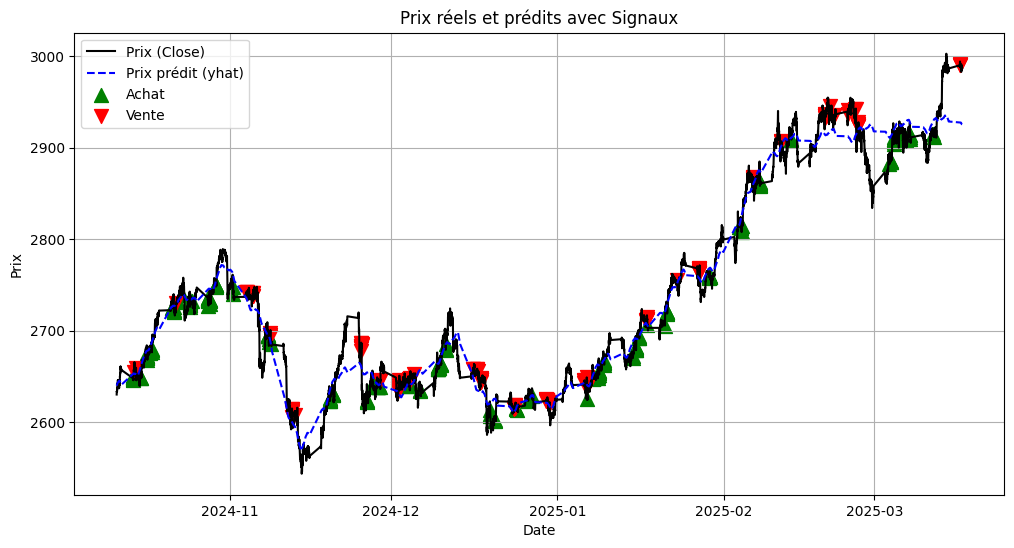

In [71]:
# Visualisation
plt.figure(figsize=(12, 6))
plt.plot(df['ds'], df['close'], label='Prix (Close)', color='black')
plt.plot(df['ds'], df['yhat'], label='Prix prédit (yhat)', color='blue', linestyle='--')
plt.scatter(df[df['buy_signal']]['ds'], df[df['buy_signal']]['close'], marker='^', color='green', label='Achat', s=100)
plt.scatter(df[df['sell_signal']]['ds'], df[df['sell_signal']]['close'], marker='v', color='red', label='Vente', s=100)
plt.title('Prix réels et prédits avec Signaux')
plt.xlabel('Date')
plt.ylabel('Prix')
plt.legend()
plt.grid()
plt.show()

### Étape 4 : Exécution des Ordres Automatiques sur MT5

In [72]:
import MetaTrader5 as mt5

def place_order(symbol, action, balance, risk_perc=2, sl_pips=50, tp_pips=100):
    """
    Place un ordre d'achat ou de vente sur MetaTrader 5 avec gestion du risque.

    Args:
        symbol (str): Symbole de l'actif (ex: "EURUSD").
        action (str): "BUY" ou "SELL".
        balance (float): Solde actuel du compte.
        risk_perc (float): Pourcentage du capital à risquer par trade (ex: 2%).
        sl_pips (int): Stop-loss en pips.
        tp_pips (int): Take-profit en pips.

    Returns:
        bool: True si l'ordre est passé avec succès, False sinon.
    """
    tick_info = mt5.symbol_info_tick(symbol)
    if tick_info is None:
        print(f"⚠️ Impossible d'obtenir les prix pour {symbol}")
        return False

    # Déterminer le prix d'entrée et le type d'ordre
    price = tick_info.ask if action == "BUY" else tick_info.bid
    order_type = mt5.ORDER_TYPE_BUY if action == "BUY" else mt5.ORDER_TYPE_SELL

    # Vérification du spread (optionnel, pour éviter d'entrer avec un spread trop élevé)
    spread = tick_info.ask - tick_info.bid
    if spread > 2 * sl_pips * 0.0001:  # Si le spread est supérieur à 2x le SL, on évite l'entrée
        print(f"⚠️ Spread trop élevé ({spread:.5f}) pour {symbol}, ordre annulé.")
        return False

    # Définition du montant risqué et du lot selon le risque
    risk_amount = (risk_perc / 100) * balance  # Montant risqué
    tick_size = mt5.symbol_info(symbol).point  # Taille du tick (ex: 0.0001 pour Forex, 1 pour indices)
    
    if tick_size == 0:
        print(f"⚠️ Impossible de récupérer la taille du tick pour {symbol}")
        return False
    
    lot = round(risk_amount / (sl_pips * tick_size * 10), 2)  # Ajustement pour correspondre à la taille de l'actif

    # Vérifier si le lot calculé est acceptable
    symbol_info = mt5.symbol_info(symbol)
    if lot < symbol_info.volume_min or lot > symbol_info.volume_max:
        print(f"⚠️ Lot calculé {lot} hors des limites ({symbol_info.volume_min}-{symbol_info.volume_max})")
        return False

    # Définition des niveaux de Stop-Loss (SL) et Take-Profit (TP)
    sl = price - sl_pips * tick_size if action == "BUY" else price + sl_pips * tick_size
    tp = price + tp_pips * tick_size if action == "BUY" else price - tp_pips * tick_size

    # Construction de la requête de trade
    request = {
        "action": mt5.TRADE_ACTION_DEAL,
        "symbol": symbol,
        "volume": lot,
        "type": order_type,
        "price": price,
        "sl": sl,
        "tp": tp,
        "deviation": 20,
        "magic": int(datetime.now().timestamp()),
        "comment": "Trade via Python",
        "type_time": mt5.ORDER_TIME_GTC,
        "type_filling": mt5.ORDER_FILLING_FOK
    }

    # Envoi de l'ordre
    order_result = mt5.order_send(request)

    # Vérification de l'exécution de l'ordre
    if order_result.retcode != mt5.TRADE_RETCODE_DONE:
        print(f"⚠️ Erreur lors de l'envoi de l'ordre ({order_result.retcode}): {order_result.comment}")
        return False
    else:
        print(f"✅ Ordre {action} exécuté avec succès à {price:.5f} (Lot: {lot})")
        print(f"🎯 SL : {sl:.5f} | TP : {tp:.5f}")
        return True

### Visualisation des Signaux 📊

In [73]:
import matplotlib.pyplot as plt
import mplfinance as mpf

def plot_signals(df, symbol):
    """
    Affiche un graphique avec les signaux Buy/Sell, les EMA et les bandes de Bollinger.
    """
    # Sélectionner les dernières données (par exemple, 200 dernières bougies)
    df_plot = df[-200:].copy()

    # Créer les signaux Buy/Sell
    buy_signals = df_plot[df_plot['buy_signal']]
    sell_signals = df_plot[df_plot['sell_signal']]

    # Définir le style du graphique
    mc = mpf.make_marketcolors(up='g', down='r', edge='inherit', wick='inherit', volume='in')
    s = mpf.make_mpf_style(marketcolors=mc)

    # Définir les indicateurs à afficher
    apds = [
        mpf.make_addplot(df_plot['ema_50'], color='blue', linestyle='dashed', label="EMA 50"),
        mpf.make_addplot(df_plot['ema_200'], color='purple', linestyle='dotted', label="EMA 200"),
        mpf.make_addplot(df_plot['bb_upper'], color='orange', linestyle='dotted', label="BB Upper"),
        mpf.make_addplot(df_plot['bb_lower'], color='orange', linestyle='dotted', label="BB Lower"),
        mpf.make_addplot(df_plot['rsi'], panel=1, color='black', label="RSI")
    ]

    # Afficher le graphique
    mpf.plot(
        df_plot, type='candle', style=s, volume=True,
        addplot=apds, title=f"📈 {symbol} - Signaux de Trading",
        ylabel='Prix', ylabel_lower='Volume',
        datetime_format='%Y-%m-%d'
    )

    # Ajouter les signaux sur le graphique
    plt.figure(figsize=(12, 8))
    plt.scatter(buy_signals.index, buy_signals['close'], marker="^", color="green", s=100, label="BUY", alpha=0.8)
    plt.scatter(sell_signals.index, sell_signals['close'], marker="v", color="red", s=100, label="SELL", alpha=0.8)
    
    for i in range(len(buy_signals)):
        plt.text(buy_signals.index[i], buy_signals['close'].iloc[i], buy_signals.index[i].strftime('%Y-%m-%d %H:%M:%S'), 
             fontsize=9, color="green", ha="center", va="bottom")

    for i in range(len(sell_signals)):
        plt.text(sell_signals.index[i], sell_signals['close'].iloc[i], sell_signals.index[i].strftime('%Y-%m-%d %H:%M:%S'),
             fontsize=9, color="red", ha="center", va="top")
    plt.legend()
    plt.show()

# Exécuter la fonction pour afficher les signaux


#### BAcktesting

In [74]:
def backtest(df, initial_balance=1000, lot_size=0.1, spread=1.5, commission=0.0, sl_pips=50, tp_pips=100):
    """
    Effectue un backtest en intégrant les signaux de trading, le spread, le stop-loss (SL) et le take-profit (TP).
    
    Paramètres :
    - df : DataFrame contenant les prix et les signaux
    - initial_balance : Solde initial du compte
    - lot_size : Taille de position en lots (0.1 lot = 10 000 unités)
    - spread : Spread moyen en pips
    - commission : Commission par trade
    - sl_pips : Stop-Loss en pips
    - tp_pips : Take-Profit en pips
    """
    balance = initial_balance
    position = 0
    entry_price = 0
    trade_log = []

    # Conversion pips en valeur monétaire (1 pip = 0.0001 pour forex majeurs)
    pip_value = 10 * lot_size  # Valeur d'un pip pour 0.1 lot = 1 €

    for i in range(len(df)):
        close_price = df['close'].iloc[i]

        # 📈 Achat
        if df['buy_signal'].iloc[i] and position == 0:
            entry_price = close_price + (spread * 0.0001)  # Achat avec spread
            position = lot_size
            trade_log.append(f"🟢 ACHAT à {entry_price:.5f} le {df.index[i]}")

        # 📉 Vente (fermeture de position)
        elif df['sell_signal'].iloc[i] and position > 0:
            exit_price = close_price - (spread * 0.0001)  # Vente avec spread
            profit_pips = (exit_price - entry_price) / 0.0001  # Gain en pips
            profit = profit_pips * pip_value - commission  # Profit ajusté
            balance += profit
            position = 0  # Fermeture de la position
            
            trade_log.append(f"🔴 VENTE à {exit_price:.5f} | Gain : {profit:.2f} € ({profit_pips:.1f} pips) | Nouveau solde : {balance:.2f} €")

        # 📌 Gestion du Stop-Loss / Take-Profit
        if position > 0:
            # Définir SL et TP
            sl_price = entry_price - (sl_pips * 0.0001)
            tp_price = entry_price + (tp_pips * 0.0001)

            if close_price <= sl_price:  # Stop-Loss touché
                loss_pips = (sl_price - entry_price) / 0.0001
                loss = loss_pips * pip_value - commission
                balance += loss
                position = 0
                trade_log.append(f"⛔ STOP-LOSS à {sl_price:.5f} | Perte : {loss:.2f} € ({loss_pips:.1f} pips) | Nouveau solde : {balance:.2f} €")
                
            elif close_price >= tp_price:  # Take-Profit atteint
                profit_pips = (tp_price - entry_price) / 0.0001
                profit = profit_pips * pip_value - commission
                balance += profit
                position = 0
                trade_log.append(f"✅ TAKE-PROFIT à {tp_price:.5f} | Gain : {profit:.2f} € ({profit_pips:.1f} pips) | Nouveau solde : {balance:.2f} €")

    # 🔎 Résumé final
    print("\n💰 Résumé du backtest :")
    for trade in trade_log:
        print(trade)

    print(f"\n💰 Solde final : {balance:.2f} € | P&L Total : {balance - initial_balance:.2f} €")


# 🚀 Exécuter le backtest avec les nouvelles améliorations
backtest(df)

    
 


💰 Résumé du backtest :
🟢 ACHAT à 2648.17415 le 88
✅ TAKE-PROFIT à 2648.18415 | Gain : 100.00 € (100.0 pips) | Nouveau solde : 1100.00 €
🟢 ACHAT à 2649.70815 le 90
✅ TAKE-PROFIT à 2649.71815 | Gain : 100.00 € (100.0 pips) | Nouveau solde : 1200.00 €
🟢 ACHAT à 2649.13315 le 92
✅ TAKE-PROFIT à 2649.14315 | Gain : 100.00 € (100.0 pips) | Nouveau solde : 1300.00 €
🟢 ACHAT à 2648.80615 le 94
⛔ STOP-LOSS à 2648.80115 | Perte : -50.00 € (-50.0 pips) | Nouveau solde : 1250.00 €
🟢 ACHAT à 2645.85015 le 96
✅ TAKE-PROFIT à 2645.86015 | Gain : 100.00 € (100.0 pips) | Nouveau solde : 1350.00 €
🟢 ACHAT à 2646.52915 le 98
✅ TAKE-PROFIT à 2646.53915 | Gain : 100.00 € (100.0 pips) | Nouveau solde : 1450.00 €
🟢 ACHAT à 2652.18415 le 143
✅ TAKE-PROFIT à 2652.19415 | Gain : 100.00 € (100.0 pips) | Nouveau solde : 1550.00 €
🟢 ACHAT à 2649.93615 le 146
✅ TAKE-PROFIT à 2649.94615 | Gain : 100.00 € (100.0 pips) | Nouveau solde : 1650.00 €
🟢 ACHAT à 2647.75115 le 235
✅ TAKE-PROFIT à 2647.76115 | Gain : 100.00 

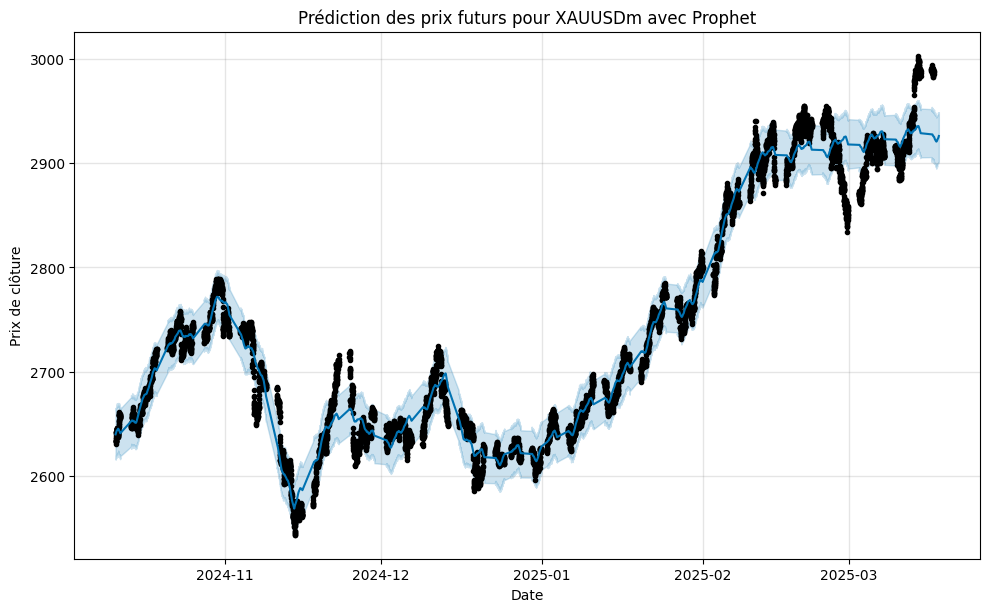

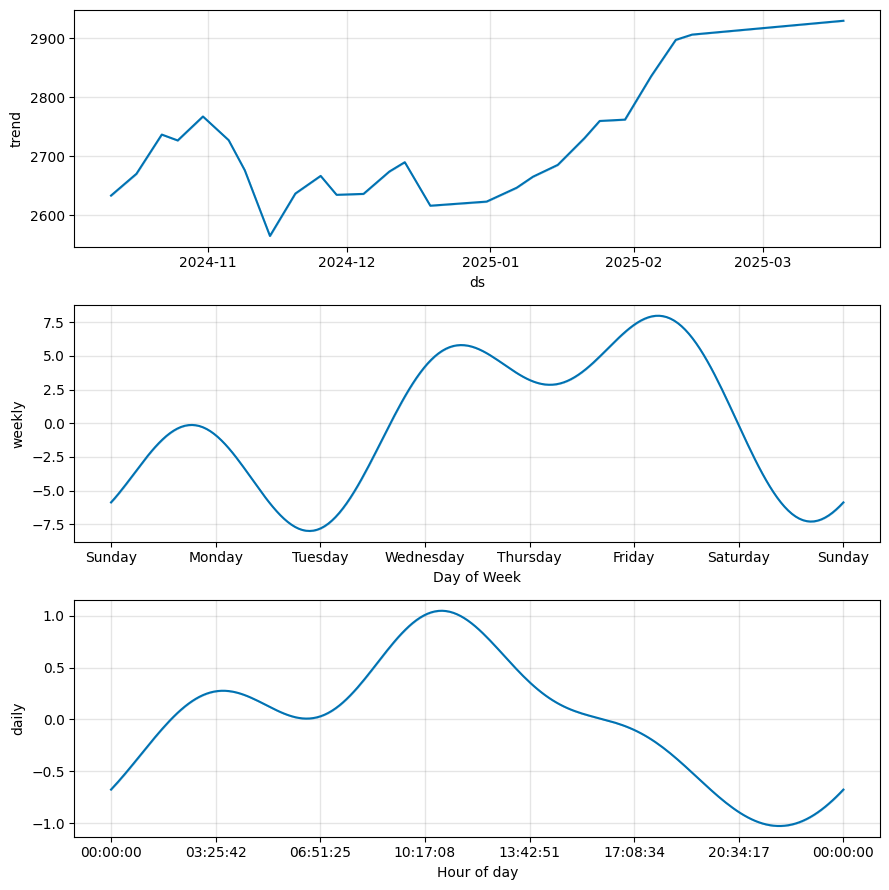

In [75]:
import matplotlib.pyplot as plt

# Tracer les données historiques et les prédictions
fig = model.plot(forecast)
plt.title(f"Prédiction des prix futurs pour {symbol} avec Prophet")
plt.xlabel("Date")
plt.ylabel("Prix de clôture")
plt.show()

# Tracer les composantes (tendance, saisonnalité)
fig2 = model.plot_components(forecast)
plt.show()

In [76]:
# # Exporter avec un séparateur personnalisé (par exemple, un point-virgule)
# df.to_csv('nom_du_fichier.csv', sep=';', index=False, encoding='utf-8')
# pd.read

In [77]:
# def get_new_data():
#     """Simule l'acquisition de nouvelles données de marché en temps réel."""
#     return {
#         'ds': pd.Timestamp.now(),
#         'y': round(random.uniform(100, 200), 2),
#         'high': round(random.uniform(150, 200), 2),
#         'low': round(random.uniform(100, 150), 2)
#     }

# def update_signals(df):
#     """Calcule les signaux d'achat et de vente."""
#     df['ema_20'] = ta.trend.ema_indicator(df['y'], window=20)
#     df['ema_50'] = ta.trend.ema_indicator(df['y'], window=50)
#     df['rsi'] = ta.momentum.rsi(df['y'], window=14)
    
#     df['buy_signal'] = (df['ema_20'] > df['ema_50']) & (df['rsi'] < 40)
#     df['sell_signal'] = (df['ema_20'] < df['ema_50']) & (df['rsi'] > 60)
    
#     return df
# def monitor_market():
#     """Boucle infinie qui surveille le marché et détecte les signaux."""
#     df = pd.DataFrame(columns=['ds', 'y', 'high', 'low'])
    
#     while True:
#         new_data = get_new_data()
#         df = pd.concat([df, pd.DataFrame([new_data])], ignore_index=True)
        
#         if len(df) > 50:
#             df = update_signals(df)
            
#             latest = df.iloc[-1]
#             if latest['buy_signal']:
#                 print(f"🟢 Achat détecté à {latest['ds']} - Prix : {latest['y']:.2f}")
#             elif latest['sell_signal']:
#                 print(f"🔴 Vente détectée à {latest['ds']} - Prix : {latest['y']:.2f}")
        
#         time.sleep(5)  # Pause de 5 secondes avant de vérifier à nouveau

# # Démarrer la surveillance du marché
# monitor_market()

In [78]:
print(df.columns)


Index(['time', 'open', 'high', 'low', 'close', 'tick_volume', 'spread',
       'real_volume', 'ds', 'y', 'yhat', 'ema_20', 'ema_50', 'rsi', 'adx',
       'atr', 'buy_signal', 'sell_signal', 'tp', 'sl', 'exit'],
      dtype='object')


In [79]:
import MetaTrader5 as mt5
import pandas as pd
import numpy as np
import ta
from datetime import datetime

# Initialiser MetaTrader 5
mt5_path = "C:\\Program Files\\MetaTrader 5\\terminal64.exe"
if not mt5.initialize(path=mt5_path):
    print("Erreur d'initialisation de MT5 :", mt5.last_error())
    exit()

# Vérifier la connexion
account_info = mt5.account_info()
if account_info is None:
    print("Impossible de récupérer les informations du compte :", mt5.last_error())
    mt5.shutdown()
    exit()
print(f"Connexion réussie à MetaTrader 5 - Compte : {account_info.login}")

# Vérification de la disponibilité du symbole
symbol = "XAUUSDm"
symbols = mt5.symbols_get()
available_symbols = [s.name for s in symbols]
if symbol not in available_symbols:
    print(f"{symbol} n'est pas disponible sur votre compte MT5.")
    exit()
else:
    print(f"{symbol} est bien disponible.")

# Récupération des données
RISK_PERC = 1.5
timeframe = mt5.TIMEFRAME_M5

data = mt5.copy_rates_from_pos(symbol, timeframe, 0, 5000)
if data is None:
    print(f"Erreur lors de la récupération des données pour {symbol} :", mt5.last_error())
    mt5.shutdown()
    exit()

df = pd.DataFrame(data)
df['time'] = pd.to_datetime(df['time'], unit='s')
df.set_index('time', inplace=True)

# Vérification et correction du volume
df['tick_volume'] = df.get('tick_volume', 0)

# Ajout des indicateurs techniques
df['atr'] = ta.volatility.average_true_range(df['high'], df['low'], df['close'], window=14)
df['donchian_high'] = df['high'].rolling(window=20).max()
df['donchian_low'] = df['low'].rolling(window=20).min()
df['ema_20'] = ta.trend.ema_indicator(df['close'], window=20)
df['ema_50'] = ta.trend.ema_indicator(df['close'], window=50)
df['rsi'] = ta.momentum.rsi(df['close'], window=14)
df['adx'] = ta.trend.adx(df['high'], df['low'], df['close'], window=14)

def fractals(df):
    df['fractal_high'] = (df['high'].shift(2) > df['high'].shift(1)) & (df['high'].shift(2) > df['high']) & \
                         (df['high'].shift(2) > df['high'].shift(3)) & (df['high'].shift(2) > df['high'].shift(4))
    df['fractal_high'] = df['fractal_high'].shift(2)
    return df

df = fractals(df)

# Détection des signaux
df['breakout'] = (df['close'] > df['donchian_high'].shift(1)) & (df['tick_volume'] > df['tick_volume'].rolling(10).mean())
df['buy_signal'] = df['breakout'] & (df['ema_20'] > df['ema_50']) & (df['rsi'] < 55) & (df['adx'] > 18)
df['sell_signal'] = df['breakout'] & (df['ema_20'] < df['ema_50']) & (df['rsi'] > 60) & (df['adx'] > 18)

# Logs pour vérifier les signaux
def debug_signals(df):
    for index, row in df.iterrows():
        print(f"{index} | Close: {row['close']} | EMA20: {row['ema_20']} | EMA50: {row['ema_50']} | RSI: {row['rsi']} | ADX: {row['adx']} | Buy: {row['buy_signal']} | Sell: {row['sell_signal']}")
debug_signals(df.tail(10))

# Vérification des données
print(df[['close', 'donchian_high', 'tick_volume', 'ema_20', 'ema_50', 'rsi', 'adx']].tail())
print(df[df['buy_signal'] | df['sell_signal']][['close', 'buy_signal', 'sell_signal']])

def backtest_signals(df, initial_balance=500, risk_percent=1.5):
    balance = initial_balance
    position = 0
    trades = []
    equity = [initial_balance]
    for i in range(1, len(df)):
        close = df['close'].iloc[i]
        atr = df['atr'].iloc[i]
        lot_size = (balance * risk_percent / 100) / (max(atr, 0.1) * 100)
        if position == 0:
            if df['buy_signal'].iloc[i]:
                position = 1
                entry_price = close
                tp = entry_price + (atr * 2.5)
                sl = entry_price - (atr * 2.5)
                trades.append({'entry': entry_price, 'type': 'buy', 'lot': lot_size, 'tp': tp, 'sl': sl})
            elif df['sell_signal'].iloc[i]:
                position = -1
                entry_price = close
                tp = entry_price - (atr * 2.5)
                sl = entry_price + (atr * 2.5)
                trades.append({'entry': entry_price, 'type': 'sell', 'lot': lot_size, 'tp': tp, 'sl': sl})
        elif position == 1 and (close >= tp or close <= sl):
            balance += ((tp if close >= tp else sl) - entry_price) * lot_size * 100
            trades[-1]['exit'] = tp if close >= tp else sl
            position = 0
        elif position == -1 and (close <= tp or close >= sl):
            balance += (entry_price - (tp if close <= tp else sl)) * lot_size * 100
            trades[-1]['exit'] = tp if close <= tp else sl
            position = 0
        equity.append(balance)
    win_rate = len([t for t in trades if t.get('profit', 0) > 0]) / len(trades) if trades else 0
    print(f"\n💰 Solde final : {balance:.2f} | Trades : {len(trades)} | Taux de réussite : {win_rate:.2%}")
    return trades, equity

trades, equity = backtest_signals(df)
print("\n📊 Signaux détectés :")
print(f"🟢 Nombre de signaux d'achat : {df['buy_signal'].sum()}")
print(f"🔴 Nombre de signaux de vente : {df['sell_signal'].sum()}")


Connexion réussie à MetaTrader 5 - Compte : 408745035
XAUUSDm est bien disponible.
2025-03-18 19:45:00 | Close: 3036.622 | EMA20: 3035.9904159421612 | EMA50: 3034.3059349711652 | RSI: 58.83603719119365 | ADX: 29.140461272021327 | Buy: False | Sell: False
2025-03-18 19:50:00 | Close: 3037.352 | EMA20: 3036.1200906143363 | EMA50: 3034.425388501708 | RSI: 63.232306485309856 | ADX: 28.775936560777073 | Buy: False | Sell: False
2025-03-18 19:55:00 | Close: 3035.615 | EMA20: 3036.0719867463044 | EMA50: 3034.4720399330135 | RSI: 49.64571489585293 | ADX: 26.986501972690487 | Buy: False | Sell: False
2025-03-18 20:00:00 | Close: 3035.728 | EMA20: 3036.0392261037996 | EMA50: 3034.5212932689737 | RSI: 50.392477130893 | ADX: 25.3248841408958 | Buy: False | Sell: False
2025-03-18 20:05:00 | Close: 3034.763 | EMA20: 3035.9176807605804 | EMA50: 3034.530771964308 | RSI: 44.34438863283036 | ADX: 24.493715344549404 | Buy: False | Sell: False
2025-03-18 20:10:00 | Close: 3034.844 | EMA20: 3035.8154254500

In [80]:
# Afficher les 10 derniers signaux
signals_detected = df[df['buy_signal'] | df['sell_signal']].tail(20)
print("\n📍 10 derniers signaux détectés (présent et futur) :")
for index, row in signals_detected.iterrows():
    signal_type = "🟢 Achat" if row['buy_signal'] else "🔴 Vente"
    exit_price = row['exit'] if 'exit' in row and pd.notna(row['exit']) else "N/A (non clôturé)"
    print(f"{row['ds']} | {signal_type} | Entrée: {row['close']:.5f} | Sortie: {exit_price} | TP: {row['tp']:.5f} | SL: {row['sl']:.5f}")



📍 10 derniers signaux détectés (présent et futur) :


KeyError: 'ds'